In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
df = pd.read_csv("Automobile_data - Automobile_data.csv")

In [32]:
df

,symboling,normalized-losses,make,fuel-type,body-style,drive-wheels,engine-location,width,height,engine-type,engine-size,horsepower,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,13495
1,3,?,alfa-romero,gas,convertible,rwd,front,64.1,48.8,dohc,130,111,21,27,16500
2,1,?,alfa-romero,gas,hatchback,rwd,front,65.5,52.4,ohcv,152,154,19,26,16500
3,2,164,audi,gas,sedan,fwd,front,66.2,54.3,ohc,109,102,24,30,13950
4,2,164,audi,gas,sedan,4wd,front,66.4,54.3,ohc,136,115,18,22,17450
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,-1,95,volvo,gas,sedan,rwd,front,68.9,55.5,ohc,141,114,23,28,16845
201,-1,95,volvo,gas,sedan,rwd,front,68.8,55.5,ohc,141,160,19,25,19045
202,-1,95,volvo,gas,sedan,rwd,front,68.9,55.5,ohcv,173,134,18,23,21485
203,-1,95,volvo,diesel,sedan,rwd,front,68.9,55.5,ohc,145,106,26,27,22470


In [33]:
df.corr(numeric_only=True)

,symboling,width,height,engine-size,city-mpg,highway-mpg,price
symboling,1.000000,-0.232919,-0.541038,-0.105790,-0.035823,0.034606,-0.085781
width,-0.232919,1.000000,0.279210,0.735433,-0.642704,-0.677218,0.718253
height,-0.541038,0.279210,1.000000,0.067149,-0.048640,-0.107358,0.132444
engine-size,-0.105790,0.735433,0.067149,1.000000,-0.653658,-0.677470,0.852995
city-mpg,-0.035823,-0.642704,-0.048640,-0.653658,1.000000,0.971337,-0.654611
highway-mpg,0.034606,-0.677218,-0.107358,-0.677470,0.971337,1.000000,-0.679048
price,-0.085781,0.718253,0.132444,0.852995,-0.654611,-0.679048,1.000000


In [34]:
df_num=df.select_dtypes(["int64","float64"])

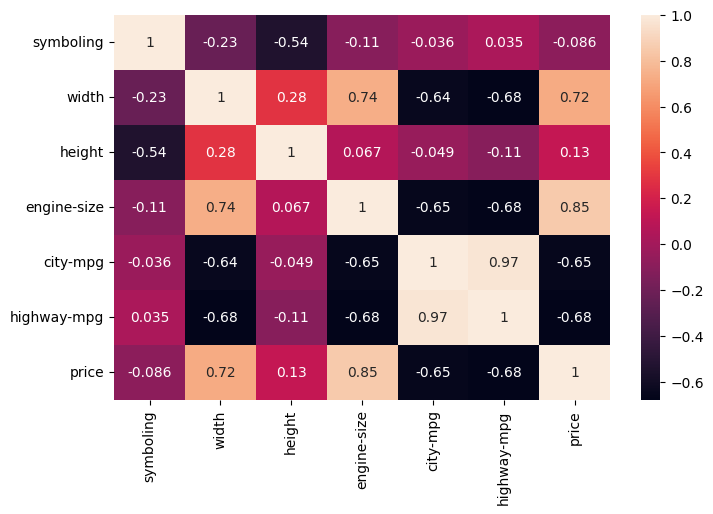

In [35]:
plt.figure(figsize=(8,5))
sns.heatmap(df_num.corr(),annot=True)
plt.show()

In [36]:
df_cat=df.select_dtypes(object)

C:\Users\arya_n0603\AppData\Local\Temp\ipykernel_21420\810974072.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_cat=df.select_dtypes(object)


In [37]:
df_new = pd.concat([df_num, df_cat], axis=1)

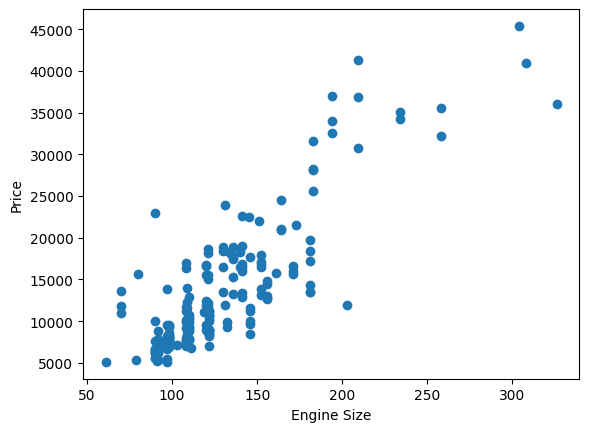

In [38]:
plt.scatter(df_new['engine-size'], df_new['price'])
plt.xlabel("Engine Size")
plt.ylabel("Price")
plt.show()

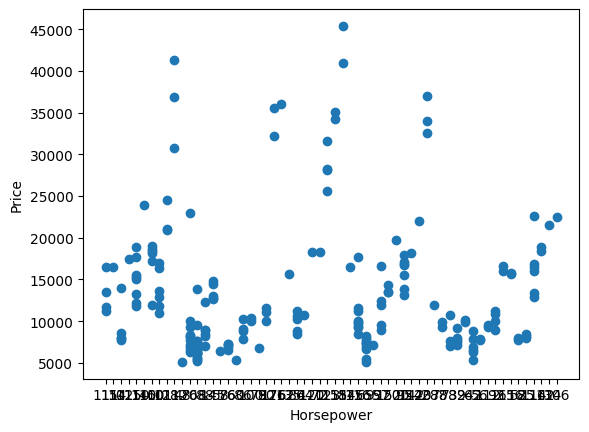

In [39]:
plt.scatter(df_new['horsepower'], df_new['price'])
plt.xlabel("Horsepower")
plt.ylabel("Price")
plt.show()

<Axes: xlabel='fuel-type', ylabel='price'>

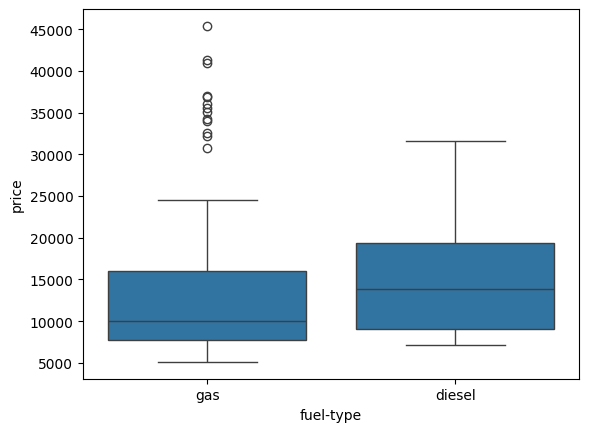

In [40]:
sns.boxplot(x= "fuel-type", y='price', data=df_new)

In [41]:
from sklearn.preprocessing import MinMaxScaler

df_minmax = df_num.copy()
for col in df_num:
    mx = MinMaxScaler()
    df_minmax[col] = mx.fit_transform(df_minmax[[col]])

print("\nMin-Max Scaled (all values between 0 and 1:)")
display(df_minmax.describe().loc[["min", "max"]])
# display(df_minmax.head())


Min-Max Scaled (all values between 0 and 1:)


,symboling,width,height,engine-size,city-mpg,highway-mpg,price
min,0.0,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [42]:
from sklearn.preprocessing import StandardScaler

df_ss = df_num.copy()
for col in df_num:
    ss = StandardScaler()
    df_ss[col] = ss.fit_transform(df_ss[[col]])

print("\nMin-Max Scaled (all values between 0 and 1:)")
display(df_ss.describe().loc[["mean", "std"]])
# display(df_ss.head())


Min-Max Scaled (all values between 0 and 1:)


,symboling,width,height,engine-size,city-mpg,highway-mpg,price
mean,4.332578e-17,1.089643e-15,-5.372396e-16,3.466062e-17,1.104807e-16,1.473076e-16,5.199093e-17
std,1.002448e+00,1.002448e+00,1.002448e+00,1.002448e+00,1.002448e+00,1.002448e+00,1.002448e+00


In [43]:
df_new['area'] = df_new['width'] * df_new['height']
df_new[['width', 'height', 'area']].head()

,width,height,area
0,64.1,48.8,3128.08
1,64.1,48.8,3128.08
2,65.5,52.4,3432.20
3,66.2,54.3,3594.66
4,66.4,54.3,3605.52


In [44]:
df_new.dtypes

symboling              int64
width                float64
height               float64
engine-size            int64
city-mpg               int64
highway-mpg            int64
price                  int64
normalized-losses        str
make                     str
fuel-type                str
body-style               str
drive-wheels             str
engine-location          str
engine-type              str
horsepower               str
area                 float64
dtype: object

In [45]:
corr_with_price = df_new.corr(numeric_only=True)["price"].drop('price')
selection = pd.DataFrame({
    "Correlation" : corr_with_price.round(3),
    "Abs" : corr_with_price.abs().round(3)
}).sort_values("Abs", ascending=False)

def decision(r):
    if pd.isna(r): return "No information (Constant)"
    return "Strong" if r> 0.70 else("Moderate" if r >= 0.30 else "Weak")

selection["Decision"] = selection["Abs"].apply(decision)
selection.drop(columns= "Abs")

,Correlation,Decision
engine-size,0.853,Strong
width,0.718,Strong
highway-mpg,-0.679,Moderate
city-mpg,-0.655,Moderate
area,0.469,Moderate
height,0.132,Weak
symboling,-0.086,Weak
